# YouTube Title Predictor

**Problem.** Small travel channels like my channel, KarmicSteps (~340 subscribers), often have
2–3 title ideas for a video and no data on which will perform better. This project predicts,
from information known at upload, whether a long-form travel video will **beat its own
channel's recent typical views**. The model is used to **rank candidate titles** before publishing.

**Data.** Videos from small travel channels (1k–100k subscribers) collected with the
YouTube Data API on 2026-10-26 (`collect_data.py`, channel selection in `explore_api.ipynb`).

**Target.** `beat_baseline = 1` if a video's views exceed the median of its channel's
previous 20 long-form videos.

**Metric.** ROC AUC, with cross-validation grouped by channel (the model is always scored on
channels it has never seen, which is the situation when scoring KarmicSteps titles).


## 1. Data cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

### 1.1 Load the data and fix the types
`COLLECTION_DATE` is fixed, so the age filter gives the same result on every run.
Empty tags and descriptions are read as NaN, so they're filled with empty text.

In [2]:
COLLECTION_DATE = pd.Timestamp("2026-10-26", tz="UTC")

videos = pd.read_csv("data/videos.csv")
print(videos.shape)
videos.head()

(21814, 9)


,video_id,channel_id,title,published_at,duration,view_count,tags,description,was_live
0,7uNx8yEasm4,UCYAIbGWcLdohnpRh-YLXzRw,Kuala Lumpur might be Asia’s most convenient city,2026-10-24T11:01:11Z,PT17M6S,20404,kuala lumpur|Kuala Lumpur vlog|Kuala Lumpur Ma...,Get 5% off your own tomtoc bag using code *SAR...,False
1,GkcnSulE3SU,UCYAIbGWcLdohnpRh-YLXzRw,This INCREDIBLE city is only 1 hour from KUALA...,2026-10-21T11:01:01Z,PT29M40S,41837,Seremban Malaysia|Seremban travel|Seremban vlo...,We left Melaka behind and took the local buses...,False
2,Vp-tGcRs2EQ,UCYAIbGWcLdohnpRh-YLXzRw,You need to know this if you're heading to Asi...,2026-10-21T07:31:21Z,PT45S,2867,travel tips|travelling asia|southeast asia|bac...,"👉 Before we dive in, comment SLYNUMBER to get ...",False
3,K9nwiOuEIOw,UCYAIbGWcLdohnpRh-YLXzRw,What's on Asia's most mysterious island? 🤔 (Fu...,2026-10-21T04:09:38Z,PT34S,13408,pulau besar|pulau besar melaka|pulau besar mal...,"Just off the coast of Melaka is Pulau Besar, a...",False
4,sSOKZa5xOCY,UCYAIbGWcLdohnpRh-YLXzRw,European countries could never... (Full video ...,2026-10-20T07:33:27Z,PT30S,14537,melaka|malacca|melaka malaysia|malacca malaysi...,We've been in Melaka for a few days and now it...,False


In [3]:
videos["tags"] = videos["tags"].fillna("")
videos["description"] = videos["description"].fillna("")
videos["published_at"] = pd.to_datetime(videos["published_at"])
videos["duration_s"] = videos["duration"].apply(lambda d: pd.Timedelta(d).total_seconds())
videos["age_days"] = (COLLECTION_DATE - videos["published_at"]).dt.days
videos.dtypes

video_id                        str
channel_id                      str
title                           str
published_at    datetime64[us, UTC]
duration                        str
view_count                    int64
tags                            str
description                     str
was_live                       bool
duration_s                  float64
age_days                      int64
dtype: object

### 1.2 Long-form only, no live streams
Shorts can be up to 3 minutes, so only videos longer than 180 s are kept. Past live streams
are removed too: their views behave differently from normal uploads.

In [4]:
videos = videos[videos['duration_s'] > 180]
print("After filtering long-form videos:", len(videos))
videos = videos[~videos["was_live"]]
print("After removing live streams:", len(videos))

After filtering long-form videos: 10890
After removing live streams: 10047


## 2. Target: beat the channel's recent median
Each video is compared with the median views of its own channel's previous 20 long-form
videos. This removes the effect of channel size and uses only information available at upload.

### 2.1 Rolling median of the previous 20 videos
`shift(1)` makes sure a video's own views are never part of its baseline (no leakage).
A channel's first 20 videos have no full baseline (`NaN`), so they're dropped in 2.2.

In [5]:
videos = videos.sort_values(["channel_id", "published_at"])         # channel first, then publish date

videos["baseline"] = (
    videos.groupby("channel_id")["view_count"]
    .transform(lambda s: s.shift(1).rolling(20, min_periods=20).median())
)

videos["beat_baseline"] = (videos["view_count"] > videos["baseline"]).astype(int)

print("Rows with a baseline:", videos["baseline"].notna().sum())
videos[["channel_id", "published_at", "view_count", "baseline", "beat_baseline"]].head(25)


Rows with a baseline: 8696


,channel_id,published_at,view_count,baseline,beat_baseline
16372,UC-9wCcxlOzrejf8ibN5blPg,2022-04-26 12:00:37+00:00,200,NaN,0
16371,UC-9wCcxlOzrejf8ibN5blPg,2022-05-26 11:00:04+00:00,249,NaN,0
16369,UC-9wCcxlOzrejf8ibN5blPg,2022-06-16 05:00:07+00:00,39528,NaN,0
16368,UC-9wCcxlOzrejf8ibN5blPg,2022-06-23 05:00:07+00:00,2077,NaN,0
16367,UC-9wCcxlOzrejf8ibN5blPg,2022-06-30 05:00:19+00:00,4754,NaN,0
16366,UC-9wCcxlOzrejf8ibN5blPg,2022-07-07 05:00:09+00:00,5565,NaN,0
16365,UC-9wCcxlOzrejf8ibN5blPg,2022-07-15 05:16:48+00:00,18524,NaN,0
16364,UC-9wCcxlOzrejf8ibN5blPg,2022-07-22 05:29:14+00:00,4725,NaN,0
16363,UC-9wCcxlOzrejf8ibN5blPg,2022-07-26 05:33:48+00:00,996,NaN,0
16362,UC-9wCcxlOzrejf8ibN5blPg,2022-07-29 05:25:50+00:00,89089,NaN,0


### 2.2 Drop rows without a baseline, apply the age window
Only videos aged **90 days to 3 years** are used as examples.

- The minimum was raised from 30 to 90 days after EDA (section 3.3): videos aged 30–90 days beat their baseline 65% of the time (median 1.4× the baseline), while every older age band is close to 50%. This is most likely a selection effect: the channels were found through search in October 2026, which favours channels that are growing right now.
- Videos older than 3 years may reflect what worked years ago.

Older videos are still used as *history* in the baselines, which is why this filter comes after 2.1.

In [6]:
df = videos[videos["baseline"].notna()]
print("With a baseline:", len(df))

df = df[(df["age_days"] >= 90) & (df["age_days"] <= (3 * 365))]
print("With age between 90 days and 3 years:", len(df))

print("Channels:", df["channel_id"].nunique())
df["beat_baseline"].value_counts(normalize=True)

With a baseline: 8696
With age between 90 days and 3 years: 3479
Channels: 54


beat_baseline
0    0.507617
1    0.492383
Name: proportion, dtype: float64

In [7]:
per_channel = df["channel_id"].value_counts()
print(per_channel.describe())
print("Channels with < 20 videos:", (per_channel < 20).sum())

count     54.000000
mean      64.425926
std       69.331743
min        1.000000
25%       12.000000
50%       40.000000
75%       93.250000
max      272.000000
Name: count, dtype: float64
Channels with < 20 videos: 19


### 2.3 Language filter and minimum videos per channel

In [8]:
def ascii_share(title):
    letters = [c for c in title if c.isalpha()]
    if not letters:
        return 1.0
    return sum(c.isascii() for c in letters) / len(letters)

df["ascii_share"] = df["title"].apply(ascii_share)
print(df[df["ascii_share"] < 0.9]["title"].head())

1544    Uttarakhand के पहाड़ों पर बसने का सपना ?😍| Rani...
1536    आदि कैलाश ओम पर्वत यात्रा 2025 || DANGEROUS RO...
1529    भारत से KAILASH MANSAROVAR दर्शन​ || Lipulekh ...
1528    Kailash Mansarovar के बाद NEPAL पहुचँ गए ?? ||...
1527    Kailash के बाद की पहली सुबह Dharchula में ? 😳|...
Name: title, dtype: str


Channels where more than 10% of titles are in a non-Latin script (Hindi, Punjabi, Tamil, Kannada, Korean) are dropped entirely, keeping channels that publish mainly in English, like KarmicSteps. Remaining individual non-English titles are dropped too. Known limitation: mixed Hindi–English titles and Latin-script languages (e.g. Turkish) can still slip through.

In [9]:
# 1. Channel-level: share of each channel's titles that look non-English
df["non_english"] = df["ascii_share"] < 0.9
channel_share = df.groupby("channel_id")["non_english"].mean()
english_channels = channel_share[channel_share <= 0.1].index
df = df[df["channel_id"].isin(english_channels)]
print("After dropping non-English channels:", len(df), "videos,", df["channel_id"].nunique(), "channels")

# 2. Title-level: drop remaining non-English titles
df = df[~df["non_english"]]
print("After dropping non-English titles:", len(df))

# 3. Per-channel floor
counts = df["channel_id"].value_counts()
keep = counts[counts >= 20].index
df = df[df["channel_id"].isin(keep)]
print("After the 20-video floor:", len(df), "videos,", df["channel_id"].nunique(), "channels")

df["beat_baseline"].value_counts(normalize=True)


After dropping non-English channels: 2913 videos, 46 channels
After dropping non-English titles: 2910
After the 20-video floor: 2773 videos, 29 channels


beat_baseline
0    0.504147
1    0.495853
Name: proportion, dtype: float64

### 2.4 Save the clean dataset
`train.py` loads this file, so the cleaning steps don't have to be repeated.

In [10]:
df.to_csv("data/videos_clean.csv", index=False)

## 3. Exploratory data analysis

### 3.1 Target balance

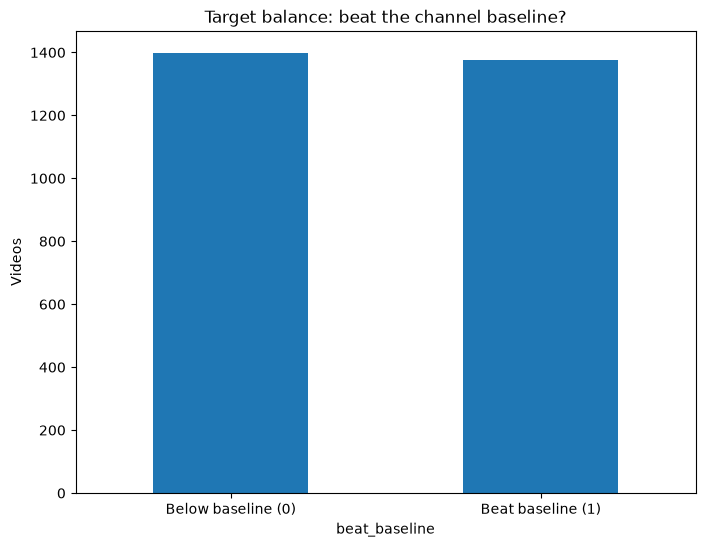

In [11]:
plt.figure(figsize=(8, 6))
df['beat_baseline'].value_counts().sort_index().plot(kind='bar')
plt.xticks([0, 1], ['Below baseline (0)', 'Beat baseline (1)'], rotation=0)
plt.ylabel('Videos')
plt.title('Target balance: beat the channel baseline?')
plt.show()

### 3.2 Videos per channel
The 29 channels contribute between 22 and 272 videos each. The four largest channels hold about 35% of all videos, so they have more weight in training, but no single channel dominates.

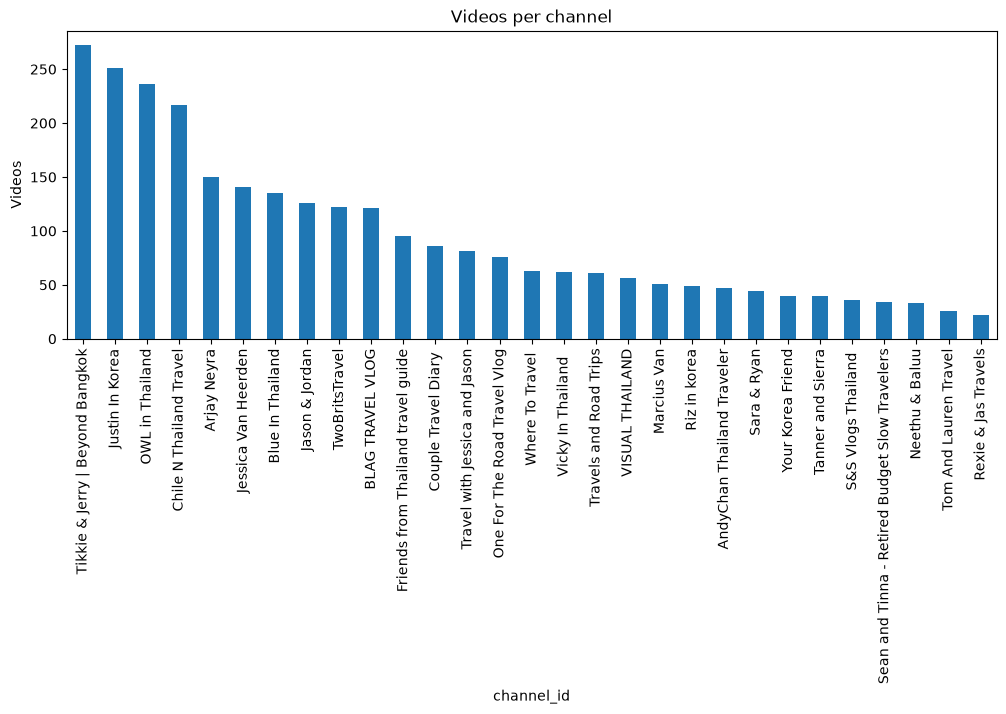

In [12]:
channel_names = pd.read_csv("data/channels.csv").set_index("channel_id")["title"]
per_channel = df["channel_id"].map(channel_names).value_counts()

per_channel.plot(kind="bar", figsize=(12, 4), title="Videos per channel")
plt.ylabel("Videos")
plt.show()

### 3.3 Does the target depend on video age?
With the original 30-day minimum, the newest videos behaved differently from the rest:

| Age band | Videos | Beat baseline | Median views ÷ baseline |
|---|---|---|---|
| 30–90 days | 192 | 65% | 1.40× |
| 90–180 days | 285 | 47% | 0.98× |
| 180–365 days | 604 | 50% | 1.00× |
| 1–2 years | 996 | 49% | 0.98× |
| 2–3 years | 885 | 51% | 1.01× |

So the minimum age was raised to 90 days (see 2.2). After the change, every age band is close to 50%:

In [13]:
df["age_band"] = pd.cut(df["age_days"], bins=[90, 180, 365, 730, 1095])
df.groupby("age_band")['beat_baseline'].mean()

age_band
(90, 180]      0.473684
(180, 365]     0.500000
(365, 730]     0.488956
(730, 1095]    0.507345
Name: beat_baseline, dtype: float64

### 3.4 Feature importance: numerical and categorical features

Same approach as the churn project in module 3:
- **Numerical features:** correlation with the target.
- **Categorical features:** the beat rate per group compared with the global rate (`diff` and `risk`),
  and mutual information.

All features are known at upload time.


In [14]:
# Create the features from the raw columns
df['published_at'] = pd.to_datetime(df['published_at'])
df['duration_min'] = df['duration_s'] / 60
df['publish_hour'] = df['published_at'].dt.hour          # UTC hour
df['publish_weekday'] = df['published_at'].dt.day_name()
df['n_tags'] = df['tags'].apply(lambda t: len(t.split('|')) if t else 0)
df['description_length'] = df['description'].str.len()
df['title_length'] = df['title'].str.len()

numerical = ['duration_min', 'publish_hour', 'n_tags', 'description_length', 'title_length']
categorical = ['publish_weekday']

In [15]:
# Correlation of each numerical feature with the target
df[numerical].corrwith(df.beat_baseline)

duration_min          0.049154
publish_hour         -0.026060
n_tags               -0.024884
description_length    0.007588
title_length          0.013376
dtype: float64

**Result:** All correlations with the target are small (|r| < 0.05). The strongest is duration
(r = 0.05: longer videos beat their baseline slightly more often). Publish hour, tag count,
description length and title length are close to 0, so on their own these features carry little signal.

In [16]:
# Beat rate per weekday, compared with the global rate
global_rate = df.beat_baseline.mean()

df_group = df.groupby('publish_weekday').beat_baseline.agg(['mean', 'count'])
df_group['diff'] = df_group['mean'] - global_rate
df_group['risk'] = df_group['mean'] / global_rate
df_group.sort_values('risk')

,mean,count,diff,risk
publish_weekday,,,,
Saturday,0.473098,539,-0.022755,0.954110
Wednesday,0.475000,440,-0.020853,0.957945
Sunday,0.480167,479,-0.015686,0.968366
Friday,0.490028,351,-0.005824,0.988254
Thursday,0.496753,308,0.000900,1.001816
Monday,0.539216,306,0.043363,1.087451
Tuesday,0.545714,350,0.049861,1.100557


In [17]:
# Mutual information between the categorical feature and the target
from sklearn.metrics import mutual_info_score

mutual_info_score(df.beat_baseline, df.publish_weekday)


0.0014769706723515852

**Result:** Monday and Tuesday uploads beat their baseline slightly more often (~54%, risk ≈ 1.09)
than Saturday and Wednesday uploads (~47%, risk ≈ 0.95). The mutual information is low, so weekday
is a weak signal. It also can't change the ranking of candidate titles, because all candidates share the same upload day.


### 3.5 Title words: most common words for beat vs not beat
The use case only varies the title, so the words themselves need to carry signal.
Each title is split into words, and the same `diff` / `risk` analysis is applied per word:
of all titles containing a word, what share beat their baseline?

In [18]:
def words(title):
    # Split a title into lowercase words and strip punctuation from the edges
    return [w.strip('.,!?|:()-–[]"\'').lower() for w in title.split()]

# One row per (word, title): each word counted once per title, stop words and empty strings skipped
rows = []
for title, target in zip(df.title, df.beat_baseline):
    for w in set(words(title)):
        if w and w not in ENGLISH_STOP_WORDS:
            rows.append({'word': w, 'beat_baseline': target})

df_words = pd.DataFrame(rows)

# Beat rate per word compared with the global rate (same idea as the churn risk ratios in module 3)
global_rate = df.beat_baseline.mean()

df_group = df_words.groupby('word').beat_baseline.agg(['mean', 'count'])
df_group['diff'] = df_group['mean'] - global_rate
df_group['risk'] = df_group['mean'] / global_rate

# Only words that appear in at least 30 titles, so the rates aren't based on a handful of videos
df_group = df_group[df_group['count'] >= 30].sort_values('risk')

print('Words that lean towards NOT beating the baseline:')
display(df_group.head(15))
print('Words that lean towards beating the baseline:')
display(df_group.tail(15))

Words that lean towards NOT beating the baseline:


,mean,count,diff,risk
word,,,,
things,0.342105,38,-0.153748,0.689933
walk,0.350000,40,-0.145853,0.705855
episode,0.367089,79,-0.128764,0.740318
places,0.371429,35,-0.124424,0.749070
tips,0.372093,43,-0.123760,0.750410
seoul,0.375000,32,-0.120853,0.756273
trip,0.379630,108,-0.116223,0.765609
volleyball,0.386364,44,-0.109489,0.779190
life,0.393258,89,-0.102594,0.793095


Words that lean towards beating the baseline:


,mean,count,diff,risk
word,,,,
da,0.625000,32,0.129147,1.260455
5,0.625000,40,0.129147,1.260455
worth,0.627907,43,0.132054,1.266317
new,0.632075,106,0.136223,1.274724
2026,0.634921,63,0.139068,1.280462
shopping,0.637500,80,0.141647,1.285664
like,0.638889,36,0.143036,1.288465
nang,0.651163,43,0.155310,1.313218
global,0.654762,84,0.158909,1.320476


**Result:** Some words clearly lean one way (overall beat rate ≈ 50%):
- **Towards beating the baseline:** concrete experiences and value words such as *hotel* (69%),
  *breakfast* (68%), *eat* (68%), *shopping* (64%), *new* (63%) and *worth* (63%, as in "is it worth it?").
- **Towards not beating it:** generic words such as *trip* (38%), *things* (34%), *places* (37%),
  *tips* (37%), *walk* (35%), *life* (39%) and *episode* (37%).

Caution: some strong words come from a single channel's series (e.g. *bar* 87%, *scholarship*,
*global*, *volleyball*), so they may reflect that channel rather than a general title effect.
Cross-validation grouped by channel (section 5) will show whether the title signal generalises
to channels the model hasn't seen. Overall, the words do carry signal, which supports using TF-IDF on titles.


## 4. Feature engineering
All features are known at upload time. They are created in one function, `add_features()`,
so `train.py` and `predict.py` can reuse exactly the same steps.

### 4.1 Video details and title statistics
- **Video details:** duration, publish hour (UTC) and weekday, number of tags, description length.
- **Title statistics:** length, word count, and whether the title contains a number, `?`, `!`,
  ALL-CAPS words, an emoji, or a separator (`|`, `-`).

In [19]:
def add_features(df):
    df = df.copy()

    # Video details
    df['published_at'] = pd.to_datetime(df['published_at'])
    df['duration_min'] = df['duration_s'] / 60
    df['publish_hour'] = df['published_at'].dt.hour          # UTC hour
    df['publish_weekday'] = df['published_at'].dt.day_name()
    df['n_tags'] = df['tags'].apply(lambda t: len(t.split('|')) if t else 0)
    df['description_length'] = df['description'].str.len()

    # Title statistics
    df['title_length'] = df['title'].str.len()
    df['title_words'] = df['title'].str.split().str.len()
    df['has_number'] = df['title'].str.contains(r'\d').astype(int)
    df['has_question'] = df['title'].str.contains('?', regex=False).astype(int)
    df['has_exclamation'] = df['title'].str.contains('!', regex=False).astype(int)
    # Words in capitals, ignoring single letters like "I" or "A"
    df['n_caps_words'] = df['title'].apply(lambda t: sum(w.isupper() and len(w) > 1 for w in t.split()))
    # Emojis and symbols have high Unicode codes
    df['has_emoji'] = df['title'].apply(lambda t: any(ord(c) > 0x2500 for c in t)).astype(int)
    df['has_separator'] = df['title'].str.contains(r'[|\-–]').astype(int)

    return df

df = add_features(df)

### 4.2 Do the title statistics carry signal?
Same `diff` / `risk` check as in section 3.4, for each yes/no title feature.

In [20]:
binary = ['has_number', 'has_question', 'has_exclamation', 'has_emoji', 'has_separator']

for c in binary:
    df_group = df.groupby(c).beat_baseline.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    display(df_group)

,mean,count,diff,risk
has_number,,,,
0,0.486126,1874,-0.009727,0.980383
1,0.516129,899,0.020276,1.040891


,mean,count,diff,risk
has_question,,,,
0,0.487942,2488,-0.007911,0.984046
1,0.564912,285,0.069059,1.139274


,mean,count,diff,risk
has_exclamation,,,,
0,0.495697,2324,-0.000156,0.999686
1,0.496659,449,0.000806,1.001626


,mean,count,diff,risk
has_emoji,,,,
0,0.497209,2329,0.001356,1.002735
1,0.488739,444,-0.007114,0.985653


,mean,count,diff,risk
has_separator,,,,
0,0.495025,1608,-0.000828,0.998330
1,0.496996,1165,0.001143,1.002305


**Result:** Titles with a question mark beat their baseline more often (57% vs 49%, 285 titles),
which fits the *"is it worth it?"* pattern from 3.5. Numbers help slightly (52% vs 49%).
Exclamation marks, emojis and separators make no difference (all ≈ 50%).

### 4.3 Feature lists
The numerical and categorical features go through `DictVectorizer`. The title text goes through
TF-IDF (single words and word pairs, words in at least 5 titles, English stop words removed),
which gives about 1,070 title terms. Both are fitted on training data only (section 5).

In [21]:
numerical = ['duration_min', 'publish_hour', 'n_tags', 'description_length',
             'title_length', 'title_words', 'has_number', 'has_question',
             'has_exclamation', 'n_caps_words', 'has_emoji', 'has_separator']
categorical = ['publish_weekday']

## 5. Model training

### 5.1 Train/test split by channel
The use case is a channel model hasn't seen (KarmicSteps), so the whole channel is held out:
20% of channels go to the test set. Videos form one channel are never in both train and test, otherwise the model could learn channel habits instead of title effects.

In [22]:
# Split by channel: all videos of a channel end up on the same side
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)
train_idx, test_idx = next(gss.split(df, groups=df.channel_id))

df_full_train = df.iloc[train_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

print("Full train:", len(df_full_train), "videos,", df_full_train.channel_id.nunique(), "channels")
print("Test:", len(df_test), "videos,", df_test.channel_id.nunique(), "channels")


Full train: 2226 videos, 23 channels
Test: 547 videos, 6 channels


### 5.2 Train and predict functions
`train()` fits the encoders and the model on training data only,
`predict()` reuses them. With `use_text=True`, TF-IDF title features are added next to the other features.


In [23]:
def train(df_train, y_train, C=1.0, use_text=True):
    # Numerical + categorical features
    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    # Title text: TF-IDF, put next to the other features
    tfidf = None
    if use_text:
        tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words='english')
        X_text = tfidf.fit_transform(df_train.title).toarray()
        X_train = np.hstack([X_train, X_text])

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, tfidf, model


def predict(df, dv, tfidf, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)

    if tfidf is not None:
        X_text = tfidf.transform(df.title).toarray()
        X = np.hstack([X, X_text])

    return model.predict_proba(X)[:, 1]

### 5.3 Logistic regression: without vs with title text
5-fold cross-validation on the full train set, grouped by channel (`GroupKFold`), so every
validation fold contains only unseen channels. `C` is the regularisation strength (smaller = stronger).

In [24]:
gkf = GroupKFold(n_splits=5)

for use_text in [False, True]:
    for C in [0.01, 0.1, 1, 10]:
        scores = []

        for train_idx, val_idx in gkf.split(df_full_train, groups=df_full_train.channel_id):
            df_train = df_full_train.iloc[train_idx]
            df_val = df_full_train.iloc[val_idx]

            dv, tfidf, model = train(df_train, df_train.beat_baseline.values, C=C, use_text=use_text)
            y_pred = predict(df_val, dv, tfidf, model)
            scores.append(roc_auc_score(df_val.beat_baseline, y_pred))

        print('text=%s C=%s  AUC %.3f +- %.3f' % (use_text, C, np.mean(scores), np.std(scores)))

text=False C=0.01  AUC 0.509 +- 0.025
text=False C=0.1  AUC 0.498 +- 0.016
text=False C=1  AUC 0.495 +- 0.015
text=False C=10  AUC 0.495 +- 0.015
text=True C=0.01  AUC 0.512 +- 0.024
text=True C=0.1  AUC 0.518 +- 0.022
text=True C=1  AUC 0.545 +- 0.026
text=True C=10  AUC 0.546 +- 0.019


**Result:** Without title text the model is no better than chance (AUC ≈ 0.50 for every `C`):
duration, upload time, tags and description length don't predict whether a video beats its own
channel's baseline. Adding TF-IDF title features raises the AUC to about 0.55 (C = 1 or 10).
The signal is weak, which is expected, since views depend on many things a title can't capture
(thumbnail, topic, timing, the algorithm). But it is consistent across unseen channels, so titles
do carry some information. This supports the use case: ranking a few candidate titles, not predicting views.

### 5.4 Which title words does the model use?
The model is trained once on the full train set (with text, C = 1). Each feature gets a coefficient:
positive means the feature pushes towards beating the baseline, negative pushes away from it.

In [25]:
dv, tfidf, model = train(df_full_train, df_full_train.beat_baseline.values, C=1, use_text=True)

# Names of all columns: first the DictVectorizer features, then the TF-IDF title terms
feature_names = list(dv.get_feature_names_out()) + list(tfidf.get_feature_names_out())
coef = pd.Series(model.coef_[0], index=feature_names).sort_values()

print('Pushes towards NOT beating the baseline:')
display(coef.head(15).round(2))
print('Pushes towards beating the baseline:')
display(coef.tail(15).round(2))

Pushes towards NOT beating the baseline:


tokyo              -1.54
vlog               -1.25
real               -1.22
thailand 2025      -1.22
youtube            -1.20
volleyball korea   -1.19
hoi                -1.17
episode            -1.15
lunch              -1.14
vlogmas            -1.14
temples            -1.10
vlogs              -1.10
korea              -1.09
24                 -1.05
taking             -1.04
dtype: float64

Pushes towards beating the baseline:


airport        1.03
bar            1.06
flight         1.07
new            1.09
cost           1.10
backpacking    1.12
inside         1.12
philippines    1.14
cultural       1.14
study          1.20
shopping       1.21
hyderabad      1.23
itinerary      1.24
romania        1.28
job            1.56
dtype: float64

**Result:** Positive words are mostly practical and informational: *itinerary*, *cost*, *flight*,
*airport*, *job*, *study*, *shopping*, *new*. Titles that promise useful information do better.
Negative words are generic vlog labels: *vlog*, *vlogs*, *vlogmas*, *episode*, *youtube*, plus some
place names (*tokyo*, *korea*, *thailand 2025*). Some place names probably reflect one channel rather
than a general effect. Of the title statistics, a question mark has the largest coefficient (0.28),
which matches section 4.2. The other numerical features are close to 0.


### 5.5 Preparing the folds for tree models
The same features as logistic Regression (DictVectorizer + TF-IDF on titles), fitted on each training fold only. The five folds are built once and reused, so every model is compared on exactly the same splits.


In [26]:
def fit_encoder(df_train):
    # Fit the encoders on training data only
    dv = DictVectorizer(sparse=False)
    dv.fit(df_train[categorical + numerical]. to_dict(orient='records'))

    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words='english')
    tfidf.fit(df_train.title) 
    return dv, tfidf

def make_X(df, dv, tfidf):
    # Turn a dataframe into the feature matrix: other features  + title TF_IDF
    X = dv.transform(df[categorical + numerical].to_dict(orient='records'))
    X_text = tfidf.transform(df.title).toarray()
    return np.hstack([X, X_text])

# build the 5 channel-grouped folds once
folds  = [] 
for train_idx, cal_idx in gkf.split(df_full_train, groups=df_full_train.channel_id):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[cal_idx]

    dv, tfidf = fit_encoder(df_train)
    X_train = make_X(df_train, dv, tfidf)
    X_val = make_X(df_val, dv, tfidf)
    folds.append((X_train, df_train.beat_baseline.values, X_val, df_val.beat_baseline.values))

def cv_auc(model):
    #Train the model on each fold and return mean and std of the validation AUC
    scores = [] 
    for X_train, y_train, X_val, y_val in folds:
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(y_val, y_pred))
    return np.mean(scores), np.std(scores)

### 5.6 Random forest
Tuning `max_depth` (how deep each tree can grow) and `min_samples_leaf` (minimum videos per leaf),
with 200 trees.

In [27]:
for d in [5, 10, 20, None]:
    for leaf in [1, 5, 20]:
        rf = RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=leaf,
                                    random_state=1, n_jobs=-1)
        print('max_depth=%s min_samples_leaf=%s  AUC %.3f +- %.3f' % (d, leaf, *cv_auc(rf)))


max_depth=5 min_samples_leaf=1  AUC 0.529 +- 0.035
max_depth=5 min_samples_leaf=5  AUC 0.526 +- 0.030
max_depth=5 min_samples_leaf=20  AUC 0.522 +- 0.041
max_depth=10 min_samples_leaf=1  AUC 0.523 +- 0.033
max_depth=10 min_samples_leaf=5  AUC 0.524 +- 0.032
max_depth=10 min_samples_leaf=20  AUC 0.518 +- 0.037
max_depth=20 min_samples_leaf=1  AUC 0.527 +- 0.029
max_depth=20 min_samples_leaf=5  AUC 0.528 +- 0.030
max_depth=20 min_samples_leaf=20  AUC 0.515 +- 0.036
max_depth=None min_samples_leaf=1  AUC 0.516 +- 0.022
max_depth=None min_samples_leaf=5  AUC 0.523 +- 0.027
max_depth=None min_samples_leaf=20  AUC 0.515 +- 0.036


**Results:** The best random forest reaches AUC ≈ 0.53 (max_depth=5 min_samples_leaf=1), below logic regression (0.546).

### 5.7 XGBoost
Tunning `learning_rate` (eta) and `max_depth`, with 200 boosting rounds. The scikit-learn style `XGBClassifier` is used so it fits the same `cv_auc` function.

In [28]:
for eta in [0.01, 0.05, 0.1, 0.3]:
    for d in [3, 6]:
        xgb_model = XGBClassifier(n_estimators=200, learning_rate=eta, max_depth=d,
                                  random_state=1, n_jobs=-1)
        print('eta=%s max_depth=%s  AUC %.3f +- %.3f' % (eta, d, *cv_auc(xgb_model)))


eta=0.01 max_depth=3  AUC 0.504 +- 0.018
eta=0.01 max_depth=6  AUC 0.514 +- 0.018
eta=0.05 max_depth=3  AUC 0.514 +- 0.010
eta=0.05 max_depth=6  AUC 0.521 +- 0.014
eta=0.1 max_depth=3  AUC 0.517 +- 0.017
eta=0.1 max_depth=6  AUC 0.530 +- 0.017
eta=0.3 max_depth=3  AUC 0.540 +- 0.011
eta=0.3 max_depth=6  AUC 0.528 +- 0.011


### 5.8 Model selection

| Model | Best settings | CV AUC (unseen channels) |
|---|---|---|
| Logistic regression, no text | any C | ≈ 0.50 |
| **Logistic regression + title TF-IDF** | **C = 1** | **0.546** |
| Random forest | max_depth=5, min_samples_leaf=1 | 0.529 |
| XGBoost | eta=0.3, max_depth=3 | 0.540 |

Logistic regression with title text is chosen: it has the highest AUC, it is the simplest model,
and its coefficients show directly which title words help (section 5.4). Tree models don't do better
on ~1,000 sparse word columns with only ~2,200 training videos.


## 6. Final evaluation on the test channels
The chosen model (logistic regression with title TF-IDF, C = 1) is trained on all 23 training channels and evaluated once on the 6 held-out channels it has never seen.

In [29]:
dv, tfidf, model = train(df_full_train, df_full_train.beat_baseline.values, C=1, use_text=True)

y_pred = predict(df_test, dv, tfidf, model)
print('Test AUC: %.3f' % roc_auc_score(df_test.beat_baseline, y_pred))

Test AUC: 0.516


### 6.1 Ranking within each channel
The use case compares titles *within one channel*, so the AUC is also computed per test channel:
does the model rank that channel's videos better than chance (0.5)?

In [30]:
df_test['y_pred'] = y_pred

for channel, df_channel in df_test.groupby('channel_id'):
    auc = roc_auc_score(df_channel.beat_baseline, df_channel.y_pred)
    print('%-35s %3d videos  AUC %.3f' % (channel_names[channel], len(df_channel), auc))

Where To Travel                      63 videos  AUC 0.555
Sara & Ryan                          44 videos  AUC 0.579
Travel with Jessica and Jason        81 videos  AUC 0.532
AndyChan Thailand Traveler           47 videos  AUC 0.420
Tanner and Sierra                    40 videos  AUC 0.390
Tikkie & Jerry | Beyond Bangkok     272 videos  AUC 0.550


**Result:** The test AUC is 0.52, lower than the cross-validation AUC (0.55). With only 6 test
channels, the result depends a lot on which channels end up in the test set. Per channel, the model
ranks better than chance for 4 of 6 channels (0.53–0.58: Sara & Ryan, Where To Travel, Tikkie & Jerry,
Travel with Jessica and Jason) and worse for 2 (AndyChan Thailand Traveler 0.42, Tanner and Sierra 0.39).

**Conclusion:** Title wording carries a small but real signal: practical, informational titles
(*cost*, *itinerary*, *worth it?*) tend to do better than generic vlog labels (*vlog*, *episode*).
Most of a video's performance depends on things the model can't see (thumbnail, topic, timing,
the algorithm). The model is useful for ranking a few candidate titles as a second opinion,
not for predicting views.